# TP1 · Task 3: Individual and ensemble prediction models
## Classification of abnormal electric-vehicle charging sessions

**Course:** Mineração de Dados (MINDD), 2026/2027, 1st semester, ISEP / DEI

**Dataset:** educational version of the *China EV Charging Dataset* (Zhang et al., 2025). It has 441,077 charging sessions,
92 charging posts, 13 stations and 3 districts, from 2020 to 2021.

Task 3 asks three things: which kinds of information contribute to the prediction (an ablation by feature group), how individual
classifiers of different modelling principles perform, and whether ensembles improve on them. Everything runs under the evaluation
protocol that we fixed in Task 2 (`prepared/task2_protocol.json`): the same four expanding-window folds, the same metrics and the
same baselines. The rows of the final test period are dropped right after the file is read, and no decision threshold is chosen here.

### How to read this notebook

| # | Section | Requirement of the Task 3 brief |
|---|---------|---------------------------------|
| 1 | Setup | — |
| 2 | Data, folds and baselines from Task 2 | the protocol that every result below follows |
| 3 | Feature-group ablation | four nested feature sets; tariff against time of day, post history, user history, consistency over time, operational and ethical concerns |
| 4 | Individual models | classifiers of at least three modelling principles, justified by data types, imbalance, assumptions, interpretability and cost |
| 5 | Ensemble models | at least three ensemble principles, with temporally out-of-fold stacking |
| 6 | Comparison and conclusions | all models against the baselines, fold by fold |
| 7 | Saved files and decision log | — |

Preprocessing values and model parameters are fitted on the training rows of each fold and applied unchanged to its validation
quarter. Feature-set and hyperparameter choices use the unweighted mean PR-AUC over the four development folds, read together
with the paired differences, as planned in Task 2 (Section 8). These are model-selection results; the separate test period is
reserved for the final evaluation (Section 6.4).

---
## 1. Setup

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.naive_bayes import CategoricalNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, KBinsDiscretizer, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler)
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
DATA_PATH = Path("Charging_Data_educational.csv")
OUT_DIR = Path("prepared")
FIG_DIR = OUT_DIR / "figures_task3"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "is_Abnormal"
NORMAL_CAUSES = {"Charging ends normally", "User stops charging"}      # every other end cause is abnormal (Task 1, Section 5)

# Everything below that defines the evaluation comes from the Task 2 files, so the two tasks cannot drift apart.
PROTOCOL = json.loads((OUT_DIR / "task2_protocol.json").read_text())
FEATURE_GROUPS = json.loads((OUT_DIR / "feature_groups.json").read_text())
BURN_IN_END = pd.Timestamp(PROTOCOL["temporal"]["burn_in_end"])
TEST_START = pd.Timestamp(PROTOCOL["temporal"]["test_start"])
ALERT_BUDGETS = tuple(PROTOCOL["metrics"]["operational"]["alert_budgets"])
GROUPS = FEATURE_GROUPS["groups"]

# Practical tolerance for small PR-AUC differences, read together with the paired fold results.
# The descriptive bootstrap in Section 3.3 gives context; this is not a significance threshold.
TOLERANCE = 0.005

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)
C_NORMAL, C_ABN, C_GREY, C_ORANGE, C_GREEN, C_PURPLE = "#4C72B0", "#C44E52", "#7F7F7F", "#E1A730", "#2a9d8f", "#8172B3"

DECISIONS = []


def log_decision(section, topic, decision, evidence):
    """Store a decision together with its evidence (the full log is shown in Section 7)."""
    DECISIONS.append({"section": section, "topic": topic, "decision": decision, "evidence": evidence})


def savefig(fig, name):
    """Save a figure for the report and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

---
## 2. Data, folds and baselines from Task 2

We load only the columns of the 29 eligible features and the three columns that define the target and the fold boundaries
(`Start Time`, `End Time`, `end_cause`). Right after reading the file we drop the burn-in and the test rows and only count
them, before the target or any feature is built. No label of a test session is ever computed, and the test sessions are not in memory for the
rest of the notebook.

In [2]:
RENAME = {   # same short names as in Task 1 and Task 2
    "UserID": "user_id", "Charging Post ID": "post_id", "Location Information": "location", "District Name": "district",
    "Start Time": "start_time", "End Time": "end_time", "Temperature(℃)": "temperature",
    "Relative Humidity(%)": "humidity", "Precipitation(mm)": "precipitation",
}
INVERSE_RENAME = {short: original for original, short in RENAME.items()}
DERIVED = {"hour": "Start Time", "dow": "Start Time", "rain_flag": "Precipitation(mm)"}     # features built from one column (Task 1, Section 12)

features_all = [f for group in GROUPS.values() for f in group]
needed = {DERIVED.get(f, INVERSE_RENAME.get(f, f)) for f in features_all} | {"Start Time", "End Time", "end_cause"}
df = pd.read_csv(DATA_PATH, usecols=sorted(needed)).rename(columns=RENAME)
df["start_time"] = pd.to_datetime(df["start_time"], format="%Y-%m-%d %H:%M:%S")
n_total = len(df)
n_burn_in = int((df["start_time"] < BURN_IN_END).sum())
n_test = int((df["start_time"] >= TEST_START).sum())
df = df[(df["start_time"] >= BURN_IN_END) & (df["start_time"] < TEST_START)].reset_index(drop=True)   # the test rows go here, before any label or feature exists

for col in ("location", "district", "tariff_period", "end_cause"):
    df[col] = df[col].str.strip()
df["end_time"] = pd.to_datetime(df["end_time"], format="%Y-%m-%d %H:%M:%S")
df["hour"] = df["start_time"].dt.hour.astype("int8")
df["dow"] = df["start_time"].dt.dayofweek.astype("int8")
df["rain_flag"] = (df["precipitation"] > 0).astype("int8")
df[TARGET] = (~df["end_cause"].isin(NORMAL_CAUSES)).astype("int8")

print(f"File: {n_total:,} sessions | burn-in removed: {n_burn_in:,} | test removed: {n_test:,}")
print(f"Development data: {len(df):,} sessions ({df['start_time'].min().date()} to {df['start_time'].max().date()}), "
      f"abnormal share {df[TARGET].mean():.2%}")
print(f"Features available: {len(features_all)} in {len(GROUPS)} groups")
assert df["start_time"].max() < TEST_START and len(features_all) == 29

File: 441,077 sessions | burn-in removed: 14,017 | test removed: 80,081
Development data: 346,979 sessions (2020-04-01 to 2021-09-30), abnormal share 18.54%
Features available: 29 in 7 groups


### 2.1 The four temporal folds

The folds are rebuilt from the boundaries stored in the Task 2 protocol, with the same purge rule and the same assertions. Fold *k* trains on
every labelled development session that started and ended before its validation quarter, and validates on that quarter.

In [3]:
def temporal_folds(frame, protocol=PROTOCOL):
    """Expanding-window folds of Task 2: train = sessions that started AND ended before the validation quarter (purge),
    valid = sessions that started inside the quarter."""
    folds = []
    for spec in protocol["temporal"]["folds"]:
        lo, hi = pd.Timestamp(spec["validate_from"]), pd.Timestamp(spec["validate_before"])
        folds.append({"fold": spec["fold"], "lo": lo, "hi": hi,
                      "train": frame.index[(frame["start_time"] < lo) & (frame["end_time"] < lo)],
                      "valid": frame.index[(frame["start_time"] >= lo) & (frame["start_time"] < hi)]})
    return folds


FOLDS = temporal_folds(df)
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    assert tr["start_time"].min() >= BURN_IN_END and tr["end_time"].max() < f["lo"]
    assert va["start_time"].min() >= f["lo"] and va["start_time"].max() < f["hi"]
    assert np.intersect1d(f["train"], f["valid"]).size == 0
for a, b in zip(FOLDS[:-1], FOLDS[1:]):
    assert a["hi"] == b["lo"] and np.isin(a["train"], b["train"]).all()
for f, spec in zip(FOLDS, PROTOCOL["temporal"]["folds"]):
    assert len(f["train"]) == spec["train_sessions"] and len(f["valid"]) == spec["validation_sessions"]      # same folds as Task 2
assert FOLDS[-1]["hi"] == TEST_START
print("The four folds match the Task 2 protocol and pass the temporal integrity checks.")

fold_table = pd.DataFrame([{"fold": f["fold"], "validation quarter": f"{f['lo'].date()} to {(f['hi'] - pd.Timedelta(days=1)).date()}",
                            "train sessions": len(f["train"]), "validation sessions": len(f["valid"]),
                            "validation abnormal share": df.loc[f["valid"], TARGET].mean()} for f in FOLDS]).set_index("fold")
display(fold_table.style.format({"train sessions": "{:,.0f}", "validation sessions": "{:,.0f}", "validation abnormal share": "{:.1%}"}))

The four folds match the Task 2 protocol and pass the temporal integrity checks.


,validation quarter,train sessions,validation sessions,validation abnormal share
fold,,,,
1,2020-10-01 to 2020-12-31,"111,470","60,364",16.8%
2,2021-01-01 to 2021-03-31,"171,832","41,797",15.8%
3,2021-04-01 to 2021-06-30,"213,641","57,542",18.2%
4,2021-07-01 to 2021-09-30,"271,182","75,769",21.1%


### 2.2 Metrics, aggregation and the cross-validation runner

The functions below are the ones of Task 2 (Sections 6 and 8), so the numbers of both notebooks are comparable. `cv_run` is the runner that every
experiment uses: for each fold it builds a fresh pipeline, fits it on that fold's training rows only, predicts the validation quarter and
stores the metrics. The predictions are kept because Sections 3 and 5 need them.

In [4]:
def alert_metrics(y, score, budget, rng):
    """Flag the top `budget` share of sessions by score (ties broken at random). Return the operational measures."""
    n = len(y)
    k = int(round(budget * n))
    order = np.lexsort((rng.random(n), -score))          # sort by -score; ties are shuffled
    flagged = np.zeros(n, dtype=bool)
    flagged[order[:k]] = True
    tp = int((y[flagged] == 1).sum())
    return {"alerts per 1,000": 1000 * k / n,
            "correct alerts per 1,000": 1000 * tp / n,
            "false alerts per 1,000": 1000 * (k - tp) / n,
            "missed per 1,000": 1000 * (int(y.sum()) - tp) / n,
            "precision": tp / k, "recall": tp / y.sum()}


def evaluate_scores(y, score, probability=None, rng=None):
    """All Task 2 metrics for one set of predictions. `probability` (optional) is used for Brier score and log-loss."""
    rng = rng or np.random.default_rng(SEED)
    y = np.asarray(y)
    prevalence = y.mean()
    out = {"abnormal share": prevalence, "PR-AUC": average_precision_score(y, score)}
    out["lift"] = out["PR-AUC"] / prevalence
    out["ROC-AUC"] = roc_auc_score(y, score)
    if probability is not None:
        out["Brier"] = brier_score_loss(y, probability)
        out["log-loss"] = log_loss(y, np.clip(probability, 1e-6, 1 - 1e-6))
    for q in ALERT_BUDGETS:
        for name, value in alert_metrics(y, score, q, rng).items():
            out[f"{name} @{q:.0%}"] = value
    return out


def summarise_folds(values, weights):
    """Aggregate one metric over the temporal folds (values and weights are indexed by fold number)."""
    v = pd.Series(values, dtype=float)
    return pd.Series({"mean (unweighted)": v.mean(),
                      "mean (weighted by validation sessions)": np.average(v, weights=weights),
                      "std across folds": v.std(ddof=1),
                      "worst fold": v.min(), "best fold": v.max(),
                      "trend per fold": np.polyfit(np.arange(1, len(v) + 1), v.to_numpy(), 1)[0]})


def paired(model, competitor):
    """Fold-by-fold difference `model - competitor` of one metric (Series indexed by fold) and its summary."""
    diff = pd.Series(model, dtype=float) - pd.Series(competitor, dtype=float)
    summary = {"mean difference": diff.mean(), "std of differences": diff.std(ddof=1), "folds won": f"{int((diff > 0).sum())} of {len(diff)}",
               "smallest difference": diff.min(), "largest difference": diff.max()}
    return diff, pd.Series(summary)


METRICS, PREDS = [], {}       # per-fold metrics and validation predictions of every experiment, keyed by experiment label


def cv_run(label, make_model, features):
    """Run one experiment under the Task 2 protocol: a fresh pipeline per fold, fitted on that fold's training rows only."""
    rows = []
    for f in FOLDS:
        tr, va = df.loc[f["train"]], df.loc[f["valid"]]
        started = time.time()
        model = make_model(features).fit(tr[features], tr[TARGET])
        if isinstance(model.named_steps["clf"], HistGradientBoostingClassifier):
            fitted = model.named_steps["clf"]
            assert not fitted.do_early_stopping_ and fitted.n_iter_ == fitted.max_iter
        p = model.predict_proba(va[features])[:, 1]
        seconds = time.time() - started
        PREDS[(label, f["fold"])] = p
        rows.append({"model": label, "fold": f["fold"], "validation sessions": len(va), "seconds": seconds,
                     **evaluate_scores(va[TARGET].to_numpy(), p, p, rng=np.random.default_rng(SEED))})
    result = pd.DataFrame(rows)
    METRICS.append(result)
    return result


def metric_table(labels, metric="PR-AUC"):
    """Fold-by-fold table of one metric for several experiments, with the mean over folds."""
    all_metrics = pd.concat(METRICS)
    t = all_metrics[all_metrics["model"].isin(labels)].pivot(index="model", columns="fold", values=metric).loc[labels]
    t.columns = [f"fold {c}" for c in t.columns]
    t["mean"] = t.mean(axis=1)
    return t

### 2.3 Baselines of Task 2

The reference results of Task 2 are computed again, with the same definitions: B0 (no skill: random scores for the ranking metrics and the constant
training prior for the probability metrics) and B1 (the 7-day failure rate of the post, which fits nothing). They are the floor and the simple rule
that every model below has to beat.

In [5]:
rng = np.random.default_rng(SEED)
rows = []
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    y = va[TARGET].to_numpy()
    prior = tr[TARGET].mean()                                            # learned inside the training fold
    s_b1 = va["post_previous_abnormal_rate_7D"].to_numpy()
    for label, score, prob in [("B0 no skill", rng.random(len(y)), np.full(len(y), prior)), ("B1 post failure rate (7 days)", s_b1, s_b1)]:
        PREDS[(label, f["fold"])] = score
        rows.append({"model": label, "fold": f["fold"], "validation sessions": len(y), **evaluate_scores(y, score, prob, rng=rng)})
METRICS.append(pd.DataFrame(rows))
BASELINES = ["B0 no skill", "B1 post failure rate (7 days)"]
b = metric_table(BASELINES)
display(b.style.format("{:.3f}"))
print(f"B1 mean PR-AUC = {b.loc[BASELINES[1], 'mean']:.3f} (Task 2 reported 0.511)")
assert abs(b.loc[BASELINES[1], "mean"] - 0.511) < 0.001

,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
B0 no skill,0.172,0.162,0.181,0.210,0.181
B1 post failure rate (7 days),0.499,0.456,0.547,0.540,0.511


B1 mean PR-AUC = 0.511 (Task 2 reported 0.511)


---
## 3. Feature-group ablation

### 3.1 Design

The brief asks for four nested feature sets, each one adding a kind of information to the previous one:

| Set | Adds | Groups of Task 1 | Features |
|-----|------|------------------|----------|
| S1 | contextual and weather variables | calendar (`hour`, `dow`), location (`post_id`, `location`, `district`), weather (4 variables) | 9 |
| S2 | tariff | `tariff_period` | 10 |
| S3 | charging-post history | 8 variables of the post history | 18 |
| S4 | user history | 10 user-history variables and `user_active_sessions_at_start` (the concurrency variable describes the account, so it goes with the user) | 29 |

We put the location in the contextual set because the post is known when the session starts. The variables of every set are those of the
Task 2 protocol, so nothing in this section uses information that is unavailable at the start of the session.

We add no new feature. The brief allows extra features if they are known at the start, but the start-time columns were already chosen in Task 1
(Sections 9 and 12), and Section 3.2 shows that one group, the post history, carries most of the signal. A new history feature would also need
its own check that every session it counts had ended before the start, which is the leak that Task 2 (Section 4) was built to exclude.

The ablation needs one model that is the same for every set, so that differences come from the information and not from
tuning. We use gradient boosting (`HistGradientBoostingClassifier`) with fixed hyperparameters (depth 6, learning rate 0.1, 200 iterations, at
least 100 sessions per leaf) that we do not tune. It handles categories, missing values and non-linear interactions directly, so one preprocessing
serves all sets, and it is strong enough for a group that holds information to show it. The conclusions are therefore for this model family. The
individual models of Section 4 are fitted afterwards on the set that this section selects.

Each step is judged by the paired difference in PR-AUC between the set with and without the group, fold by fold, as decided in
Task 2 (Section 8). We treat a gain as practically relevant when its mean is larger than our tolerance of 0.005 and it has the same sign in at
least three of the four folds. This is a selection rule, not a claim of statistical significance (Section 3.3). A group stays in the modelling set only if removing it costs more than
that tolerance.

In [6]:
def tree_view(features):
    """Preprocessing of tree-based models (Task 1, Section 13): ordinal codes for the categories (unseen category -> -1, treated as missing),
    everything else untouched, and missing values kept as NaN."""
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    rest = [c for c in features if c not in cat]
    steps = [("num", "passthrough", rest)]
    if cat:
        steps.insert(0, ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=float), cat))
    return ColumnTransformer(steps, verbose_feature_names_out=False).set_output(transform="pandas")


HGB_REFERENCE = dict(max_depth=6, learning_rate=0.1, max_iter=200, min_samples_leaf=100, early_stopping=False, random_state=SEED)


def make_reference_model(features):
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    return Pipeline([("prep", tree_view(features)),
                     ("clf", HistGradientBoostingClassifier(categorical_features=cat or None, **HGB_REFERENCE))])


S1 = GROUPS["calendar"] + GROUPS["location"] + GROUPS["weather"]
S2 = S1 + GROUPS["tariff"]
S3 = S2 + GROUPS["post_history"]
S4 = S3 + GROUPS["user_history"] + GROUPS["concurrency"]
STEPS = {"S1 context + weather": S1, "S2 + tariff": S2, "S3 + post history": S3, "S4 + user history": S4}
assert [len(s) for s in STEPS.values()] == [9, 10, 18, 29]

t0 = time.time()
for label, feats in STEPS.items():
    cv_run(label, make_reference_model, feats)
print(f"four ablation sets x four folds fitted in {time.time() - t0:.0f} s")

all_metrics = pd.concat(METRICS)
summary = all_metrics[all_metrics["model"].isin(list(STEPS))].groupby("model", sort=False)[["PR-AUC", "lift", "ROC-AUC", "Brier", "log-loss"]].mean()
summary.insert(0, "features", [len(f) for f in STEPS.values()])
print("Mean over the four folds (the baselines B0 and B1 have a PR-AUC of 0.181 and 0.511):")
display(summary.style.format({"PR-AUC": "{:.3f}", "lift": "{:.2f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
print("PR-AUC in every fold:")
display(metric_table(list(STEPS)).style.format("{:.3f}"))

four ablation sets x four folds fitted in 46 s
Mean over the four folds (the baselines B0 and B1 have a PR-AUC of 0.181 and 0.511):


,features,PR-AUC,lift,ROC-AUC,Brier,log-loss
model,,,,,,
S1 context + weather,9,0.290,1.60,0.660,0.144,0.456
S2 + tariff,10,0.290,1.60,0.659,0.144,0.456
S3 + post history,18,0.584,3.26,0.805,0.108,0.358
S4 + user history,29,0.615,3.44,0.833,0.104,0.342


PR-AUC in every fold:


,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
S1 context + weather,0.204,0.277,0.299,0.379,0.290
S2 + tariff,0.201,0.280,0.299,0.381,0.290
S3 + post history,0.560,0.532,0.614,0.630,0.584
S4 + user history,0.604,0.568,0.639,0.648,0.615


### 3.2 What each group adds

The table below gives the paired differences between consecutive sets, in PR-AUC and in ROC-AUC. The first step answers whether the tariff gives
information beyond the time of day (S1 already contains `hour` and `dow`), the second how much the post history contributes, and the third
whether the user history gives an additional benefit.

In [7]:
labels = list(STEPS)
questions = {"S2 + tariff": ("tariff beyond time of day", "S1 context + weather"),
             "S3 + post history": ("post history", "S2 + tariff"),
             "S4 + user history": ("user history", "S3 + post history")}
pr, roc = metric_table(labels, "PR-AUC"), metric_table(labels, "ROC-AUC")
rows, diffs = [], {}
for new, (question, base) in questions.items():
    d, s = paired(pr.loc[new, [c for c in pr.columns if c != "mean"]], pr.loc[base, [c for c in pr.columns if c != "mean"]])
    d_roc = (roc.loc[new, "mean"] - roc.loc[base, "mean"])
    diffs[question] = d
    rows.append({"added group": question, "PR-AUC difference (mean)": s["mean difference"], "folds with a gain": s["folds won"],
                 "smallest fold": s["smallest difference"], "largest fold": s["largest difference"], "ROC-AUC difference (mean)": d_roc})
steps_table = pd.DataFrame(rows).set_index("added group")
display(steps_table.style.format({"PR-AUC difference (mean)": "{:+.4f}", "smallest fold": "{:+.4f}", "largest fold": "{:+.4f}", "ROC-AUC difference (mean)": "{:+.4f}"}))
print("Paired PR-AUC differences by fold:")
display(pd.DataFrame(diffs).T.style.format("{:+.4f}"))

,PR-AUC difference (mean),folds with a gain,smallest fold,largest fold,ROC-AUC difference (mean)
added group,,,,,
tariff beyond time of day,+0.0006,3 of 4,-0.0033,+0.0038,-0.0013
post history,+0.2938,4 of 4,+0.2493,+0.3595,+0.1463
user history,+0.0306,4 of 4,+0.0177,+0.0441,+0.0273


Paired PR-AUC differences by fold:


,fold 1,fold 2,fold 3,fold 4
tariff beyond time of day,-0.0033,+0.0038,+0.0001,+0.0018
post history,+0.3595,+0.2515,+0.3151,+0.2493
user history,+0.0441,+0.0364,+0.0242,+0.0177


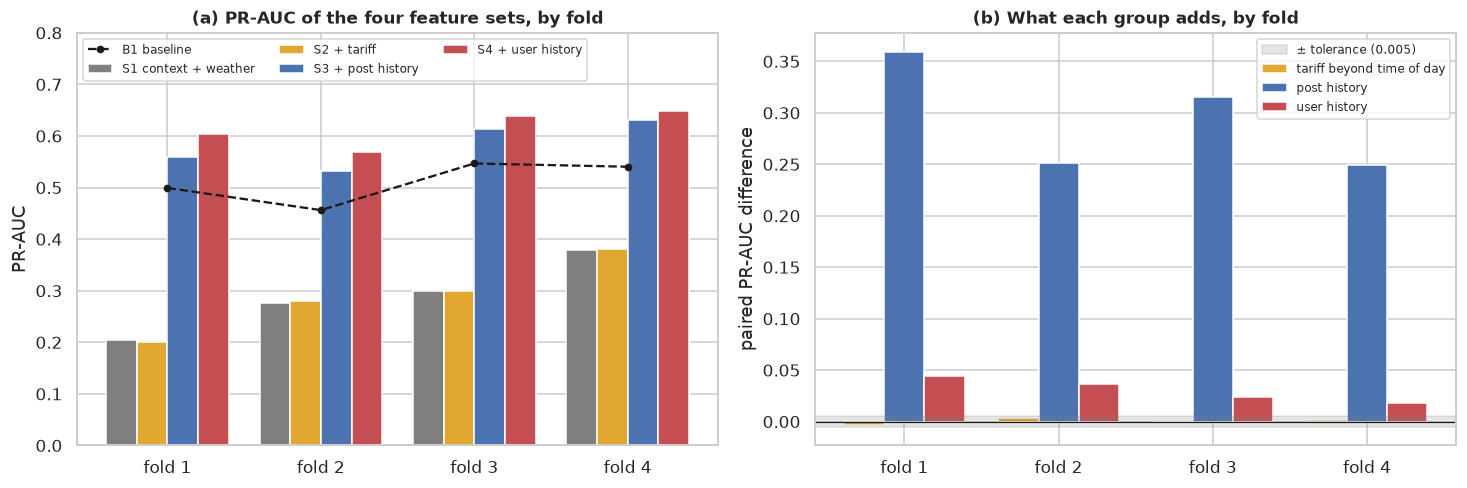

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
colors = [C_GREY, C_ORANGE, C_NORMAL, C_ABN]
width = 0.2
x = np.arange(len(FOLDS))
for i, (label, color) in enumerate(zip(labels, colors)):
    axes[0].bar(x + (i - 1.5) * width, pr.loc[label, [c for c in pr.columns if c != "mean"]], width=width, color=color, label=label)
axes[0].plot(x, metric_table([BASELINES[1]]).iloc[0, :-1], color="k", ls="--", marker="o", ms=4, label="B1 baseline")
axes[0].set_xticks(x); axes[0].set_xticklabels([f"fold {f['fold']}" for f in FOLDS]); axes[0].set_ylabel("PR-AUC")
axes[0].set_ylim(0, 0.8); axes[0].set_title("(a) PR-AUC of the four feature sets, by fold"); axes[0].legend(fontsize=8, loc="upper left", ncol=3)
for i, (question, color) in enumerate(zip(diffs, [C_ORANGE, C_NORMAL, C_ABN])):
    axes[1].bar(x + (i - 1) * 0.26, diffs[question].to_numpy(), width=0.26, color=color, label=question)
axes[1].axhspan(-TOLERANCE, TOLERANCE, color=C_GREY, alpha=0.2, label=f"± tolerance ({TOLERANCE})")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xticks(x); axes[1].set_xticklabels([f"fold {f['fold']}" for f in FOLDS]); axes[1].set_ylabel("paired PR-AUC difference")
axes[1].set_title("(b) What each group adds, by fold"); axes[1].legend(fontsize=8, loc="upper right")
fig.tight_layout()
savefig(fig, "03_2_ablation")

The contextual and weather variables alone are weak. S1 reaches a mean PR-AUC of 0.290 (lift 1.6, ROC-AUC 0.660).
Its fold values range from 0.204 to 0.379, and it stays below B1 in every quarter. In fold 4,
for example, S1 scores 0.379 against 0.540 for B1.

The tariff adds no practically relevant gain beyond the time of day. Adding `tariff_period` changes the mean PR-AUC by
+0.0006, with fold differences from -0.0033 to +0.0038, inside our tolerance. This is consistent with Task 1
(Section 4.3): the tariff period is a deterministic function of the start hour, which S1 already contains.

The post history is by far the largest contribution. It lifts the mean PR-AUC from 0.290 to 0.584
(+0.294) and the mean ROC-AUC from 0.659 to 0.805. Its gains by fold are
+0.360, +0.251, +0.315, +0.249. S3 beats B1 in every quarter, so it does more than repeat the 7-day failure rate.

The user history adds a smaller benefit: +0.031 in mean PR-AUC (0.584 to 0.615), positive in all four folds.
The gains are +0.044, +0.036, +0.024, +0.018, so the extra benefit is smaller in later quarters. The experiment does not isolate
why: the training window, the sessions and the failure pattern all change. One possible explanation is that the post history
leaves less information for the user history to add.

The ordering is consistent across quarters: S1 and S2 are close, S3 is far above them and S4 is above S3. The direction of the
history gains is consistent, while their size changes over time.

### 3.3 A practical tolerance for small differences

We use 0.005 as a practical tolerance when choosing between close results. To put its scale in context, we use the bootstrap
of the evaluation slides (MINDD-04): 100 resamples of the sessions in each validation quarter, scored with the fixed predictions of S4.

In [9]:
rng_boot = np.random.default_rng(SEED)
boot = []
for f in FOLDS:
    y = df.loc[f["valid"], TARGET].to_numpy()
    p = PREDS[("S4 + user history", f["fold"])]
    scores = [average_precision_score(y[i], p[i]) for i in (rng_boot.integers(0, len(y), len(y)) for _ in range(100))]
    boot.append({"fold": f["fold"], "validation sessions": len(y), "PR-AUC": average_precision_score(y, p), "bootstrap standard error": np.std(scores, ddof=1)})
boot = pd.DataFrame(boot).set_index("fold")
display(boot.style.format({"validation sessions": "{:,.0f}", "PR-AUC": "{:.3f}", "bootstrap standard error": "{:.4f}"}))

,validation sessions,PR-AUC,bootstrap standard error
fold,,,
1,"60,364",0.604,0.0043
2,"41,797",0.568,0.0058
3,"57,542",0.639,0.0044
4,"75,769",0.648,0.0040


The session-bootstrap standard error ranges from 0.0040 to 0.0058 across folds, of the same order as
our tolerance. This calculation describes variation in one model's score with its predictions held fixed. It does not estimate
the uncertainty of paired differences or account for dependence between sessions from the same posts, accounts and periods.

We therefore keep 0.005 as a practical selection rule and do not interpret it as a significance boundary or proof that two
models are equivalent. The paired fold differences remain the main evidence: the post-history and user-history gains are
consistently positive, whereas the tariff changes are small.

### 3.4 Do `post_id` and the tariff earn their place?

The ablation above keeps `post_id` in every set and `tariff_period` from S2 onward. Two questions remain, one left open in Task 2 (Section 4: *whether `post_id` adds
value is a question for the ablation*) and one raised by Section 3.2: the tariff is a deterministic function of the hour (Task 1, Section 4.3), and
`post_id` is an identifier that a model can memorise and whose value is unseen in training for a new post. We test both by removing them from S4, and we also
measure what the user history is worth once those two are gone, which is the cost of the privacy-preserving alternative.

In [10]:
SELECTED = [c for c in S4 if c not in ("post_id", "tariff_period")]
NO_USER = [c for c in SELECTED if c not in GROUPS["user_history"] + GROUPS["concurrency"]]
CHECKS = {"S4 without post_id": [c for c in S4 if c != "post_id"],
          "S4 without post_id and tariff (selected)": SELECTED,
          "selected without user history": NO_USER}
assert [len(f) for f in CHECKS.values()] == [28, 27, 16]

t0 = time.time()
for label, feats in CHECKS.items():
    cv_run(label, make_reference_model, feats)
print(f"three reduction checks x four folds fitted in {time.time() - t0:.0f} s")

all_labels = ["S4 + user history"] + list(CHECKS)
all_metrics = pd.concat(METRICS)
check_summary = all_metrics[all_metrics["model"].isin(all_labels)].groupby("model", sort=False)[["PR-AUC", "lift", "ROC-AUC", "Brier", "log-loss"]].mean()
check_summary.insert(0, "features", [29, 28, 27, 16])
display(check_summary.style.format({"PR-AUC": "{:.3f}", "lift": "{:.2f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
pr_c = metric_table(all_labels)
fold_cols = [c for c in pr_c.columns if c != "mean"]
rows, check_diffs = [], {}
for question, new, base in [("removing post_id from S4", "S4 without post_id", "S4 + user history"),
                            ("removing the tariff as well", "S4 without post_id and tariff (selected)", "S4 without post_id"),
                            ("removing the user history from the selected set", "selected without user history", "S4 without post_id and tariff (selected)")]:
    d, s = paired(pr_c.loc[new, fold_cols], pr_c.loc[base, fold_cols])
    check_diffs[question] = d
    rows.append({"change": question, "PR-AUC difference (mean)": s["mean difference"], "folds with a gain": s["folds won"],
                 "smallest fold": s["smallest difference"], "largest fold": s["largest difference"]})
display(pd.DataFrame(rows).set_index("change").style.format({"PR-AUC difference (mean)": "{:+.4f}", "smallest fold": "{:+.4f}", "largest fold": "{:+.4f}"}))
display(pd.DataFrame(check_diffs).T.style.format("{:+.4f}"))

three reduction checks x four folds fitted in 39 s


,features,PR-AUC,lift,ROC-AUC,Brier,log-loss
model,,,,,,
S4 + user history,29,0.615,3.44,0.833,0.104,0.342
S4 without post_id,28,0.625,3.50,0.835,0.102,0.338
S4 without post_id and tariff (selected),27,0.626,3.50,0.836,0.102,0.337
selected without user history,16,0.599,3.34,0.811,0.106,0.352


,PR-AUC difference (mean),folds with a gain,smallest fold,largest fold
change,,,,
removing post_id from S4,+0.0107,4 of 4,+0.0056,+0.0134
removing the tariff as well,+0.0003,3 of 4,-0.0004,+0.0016
removing the user history from the selected set,-0.0270,0 of 4,-0.0366,-0.0166


,fold 1,fold 2,fold 3,fold 4
removing post_id from S4,+0.0134,+0.0056,+0.0116,+0.0123
removing the tariff as well,+0.0000,+0.0016,-0.0004,+0.0000
removing the user history from the selected set,-0.0327,-0.0366,-0.0221,-0.0166


Removing `post_id` changes the mean PR-AUC from 0.615 to 0.625
(+0.0107), with gains in 4 of 4 folds (+0.0056 to +0.0134). This supports dropping the identifier.
Memorisation of devices whose behaviour changes is one possible explanation, but this comparison does not establish the cause.
We keep `location` and `district`; a new post can be represented by those fields, although genuine new-post performance is not tested here.

Removing the tariff as well changes the mean PR-AUC by +0.0003, inside the tolerance. Since it is also a deterministic
function of the hour, we drop it. This closes the question left open in Task 2 (Section 4).

The 27 selected features give a mean PR-AUC of 0.626, lift 3.50, ROC-AUC 0.836,
Brier score 0.102 and log-loss 0.337.

Without the 11 user variables, the mean PR-AUC is 0.599. The mean loss is 0.027, with a loss in every fold
(-0.037 to -0.017), so the user history stays under our rule. The user-free alternative still improves on B1
(0.599 against 0.511) and remains an option if account histories cannot be used.

### 3.5 Does the user history help everyone? Cold start

A new account (`is_new_user = 1`) has no previous personal outcomes. It can still be scored using the other predictors,
the new-user flag and the default or missing history values. We check the observed benefit of the added user group separately
for new and returning users. The table pools the validation predictions of S3 and S4 over the four folds.

In [11]:
def segment_scores(label):
    y = np.concatenate([df.loc[f["valid"], TARGET].to_numpy() for f in FOLDS])
    p = np.concatenate([PREDS[(label, f["fold"])] for f in FOLDS])
    new = np.concatenate([df.loc[f["valid"], "is_new_user"].to_numpy() for f in FOLDS])
    return y, p, new


rows = []
for label in ["S3 + post history", "S4 + user history"]:
    y, p, new = segment_scores(label)
    for flag, name in [(1, "new users"), (0, "returning users")]:
        m = new == flag
        rows.append({"feature set": label, "segment": name, "sessions": int(m.sum()), "abnormal share": y[m].mean(),
                     "PR-AUC": average_precision_score(y[m], p[m]), "ROC-AUC": roc_auc_score(y[m], p[m])})
cold = pd.DataFrame(rows).set_index(["feature set", "segment"])
display(cold.style.format({"sessions": "{:,.0f}", "abnormal share": "{:.1%}", "PR-AUC": "{:.3f}", "ROC-AUC": "{:.3f}"}))

New accounts represent 29,685 of the 235,472 validation sessions
(12.6%). Their abnormal share is higher (22.4% against 17.8%), but S4 has a lower
PR-AUC (0.519 against 0.640) and ROC-AUC (0.727 against 0.847).

For new users, S3 and S4 give PR-AUC 0.513 and 0.519, and ROC-AUC 0.730 and 0.727.
For returning users, S4 gains +0.032 in PR-AUC and +0.028 in ROC-AUC. In this pooled comparison,
the added user group benefits returning accounts more. New accounts have a small PR-AUC gain but a slight ROC-AUC loss, so
the evidence for them is mixed. Pooling combines
quarters with different prevalence and models, so this is descriptive segment evidence, not a separate temporal validation.

### 3.6 Operational and ethical concerns of each group

The brief asks which groups raise operational or ethical concerns. The table combines the conditions needed to run each group at the start of a session, the concerns, and the evidence of this notebook.

| Group | What is needed to run it | Operational or ethical concern | Evidence in this notebook | Our position |
|-------|--------------------------|--------------------------------|---------------------------|--------------|
| Calendar | Nothing: it comes from the start time | None | Part of S1, which is weak on its own (PR-AUC 0.290) | Keep |
| Station and district (`location`, `district`) | The post is known when the car is plugged in | No personal data. If alerts steer maintenance, attention concentrates on the stations with the highest risk (from about 8% to 38% abnormal in Task 1, Section 9.1), so the alerts per station should be monitored | Part of every set | Keep |
| `post_id` | The post identifier | It identifies one device and lets the model memorise it, and a new post has an identifier unseen in training | Removing it changed mean PR-AUC by +0.0107, with gains in 4 of 4 folds (Section 3.4) | Drop |
| Weather | A daily forecast per district at the start (an assumption of the brief) | None for people. If it were an observed daily total, it would contain information from after the start | Included in S1; its individual contribution is not isolated | Keep, with the assumption stated |
| Tariff | Nothing: it comes from the start time | None | Adds nothing beyond the hour (Section 3.2) | Drop, because it is redundant |
| Post history | A live record of the completed sessions of each post with their outcomes. A label exists only when a session ends, up to 24 hours later, so the record is always slightly behind. Posts without history (new ones) cannot use it | No personal data. There is a feedback effect: if alerts lead to maintenance, the failures fall and the history changes, so the model also reflects the maintenance policy | Largest contribution: +0.294 PR-AUC, in all four folds | Keep |
| User history and concurrency | The account must be identified when the session starts, and the platform must keep the outcomes of each account | It is a behaviour profile tied to a persistent identifier, which raises data-minimisation and purpose-limitation concerns. A driver who met a faulty post gets a higher risk, so the user can be blamed for a failure of the infrastructure. New users have no personal outcome history; we observe little added benefit for them (Section 3.5) | +0.031 PR-AUC, positive in 4 of 4 folds (+0.044 in fold 1, +0.018 in fold 4); pooled benefit mainly for returning users | Keep it in the comparison, because the rule requires it, but use it only for an internal ranking and never for a decision about a driver. The user-free set is the fallback (PR-AUC 0.599) |

In [12]:
log_decision("3", "Ablation design", "Four nested sets S1 to S4 with one fixed, untuned gradient-boosting model; paired fold differences with a tolerance of 0.005.",
             "Reference model handles categories, NaN and interactions; the tolerance is practical; the descriptive session bootstrap does not establish significance (Section 3.3).")
log_decision("3", "Selected feature set",
             "27 features: S4 without `post_id` and `tariff_period` (calendar, station and district, weather, post history, user history, concurrency).",
             "Removing post_id changed mean PR-AUC by +0.0107, with gains in 4 of 4 folds; tariff removal is inside the tolerance. Post history adds +0.294 and user history +0.031 on average (Sections 3.2 and 3.4).")
log_decision("3", "No new features", "No feature is added to the 29 start-time features of the Task 2 protocol.",
             "The start-time columns were chosen in Task 1 (Sections 9 and 12); the post history alone carries most of the signal (Section 3.2); "
             "a new history feature would need its own leakage check.")

---
## 4. Individual models

### 4.1 Which classifiers, and why

The brief lists five modelling principles (linear, probabilistic, instance-based, decision trees and kernel-based) and asks for at least three,
chosen and justified, instead of many without analysis. We choose three: a linear classifier, a probabilistic classifier and a decision tree. The
choice depends on what the data look like. The 27 selected features mix two categories (station and district), two circular calendar variables, weather,
skewed counts and times (Task 1, Section 9.4), bounded rates and four variables with structural missing values. About 18.5% of the sessions are
abnormal, which is a moderate imbalance. In Task 1 we decided not to resample, so the classifiers use the natural class prior and we judge them with
ranking metrics (PR-AUC, ROC-AUC) and with probability metrics (Brier score, log-loss).

| Principle | Classifier | Why it fits this problem | Assumption and risk here | Interpretability | Cost on 270k training sessions |
|-----------|------------|--------------------------|--------------------------|------------------|--------------------------------|
| Linear | Logistic regression (L2) | The failure rate of a post rises smoothly with its recent failure rate (decile curves of Task 1, Section 9.4), which a linear relationship in log-odds can represent (the slides describe logistic regression as linear in the supplied features). It outputs probabilities, which the Brier score and the cut-off `t* = 1/(1 + c)` of Task 2 need | The log-odds must be linear in the inputs, so the skewed variables need a log transform, and the U-shape of the time since the previous session is not linear. Correlated windows make single coefficients unstable (the long user windows have a VIF above 10 in Task 1, Section 12.4), and the L2 penalty controls that. The slides ask for scaled inputs, especially with a penalty, so the inputs are z-scores | High: one coefficient per input | Low: seconds |
| Probabilistic | Naive Bayes (categorical, Laplace estimate) | Few parameters, a posterior probability from Bayes' theorem and a different inductive bias from the other two. It handles the mixed types once the numbers are discretised, which is the equal-frequency binning of the course | It assumes the inputs are independent given the class (the naive assumption of the slides). They are not: the 1-, 7- and 30-day windows overlap and fleet accounts repeat. We retain the selected inputs and expect correlated history windows to make probabilities overconfident | Medium: one likelihood table per input | Low: seconds |
| Decision tree | CART tree | Thresholds on rates and gaps and their interactions (for example "recent post failure rate high and short gap since the previous session") match the shapes seen in Task 1. Its inductive bias is the one of the slides: successive thresholds cut the data into regions with similar labels. Missing values cause no trouble, and no scaling is needed | A single deep tree is unstable ("small changes in the training data can produce a different tree", MINDD-05) and overfits. Tree size controls its flexibility, so depth and leaf size are chosen on the folds | High: rules can be read | Low: seconds |

We leave out two principles. *k-nearest neighbours* (instance-based) is a lazy learner that keeps every training session and needs a distance on
inputs of the same scale, which is hard with skewed counts, rates and categories together. Each of the 42–76k validation sessions of a fold would
have to be compared with up to 270k training sessions. Subsampling the training data to make it fast would
throw away the history that gives the signal. A *kernel SVM* (kernel-based) takes a time between quadratic and cubic in the number of training sessions,
which is not feasible at this size without subsampling, and it returns a distance from the hyperplane (a score) and not a probability (MINDD-04). We therefore cover three of the five principles.

### 4.2 Preprocessing of each classifier

Every step that learns from data is fitted inside the training part of each fold, through a pipeline (Task 2, Section 7.3).

* Logistic regression uses the linear view of Task 1 (Section 13): the training maximum for the structural missing values (the indicator variables stay
  in the model), `log1p` for a fixed list of non-negative elapsed times, long-window user counts and precipitation, z-scores, one-hot codes for station and district, and sine and cosine of hour and day of week. The
  data-preparation slides recommend this cyclical encoding for circular variables: it keeps 23:00 next to 00:00, which a linear model cannot see from
  the raw hour. Task 1 decided not to cap outliers, and Section 4.4 checks that decision again.
* Naive Bayes retains all selected inputs. Numerical variables are discretised into up to 10 equal-frequency bins learned on
  the training rows, while binary variables, hour, day of week, station and district are categories. We use Laplace smoothing
  with α = 1 and reserve one code for unseen station/district values. We do not import Task 1's reduced list: its target-based
  ranking used dates that overlap the early validation folds. The bin edges and category vocabularies are fitted anew in
  every outer fold and every inner stacking fit.
* The decision tree uses the tree view of Section 3: ordinal codes for station and district, missing values kept.

The predictive-models slides advise against imposing an arbitrary numerical order on unordered categories, and the codes of the tree view do impose
one. We keep them, as decided in Task 1, because after `post_id` is dropped only 13 stations and 3 districts remain, and a tree can isolate any
single code with two threshold splits, so the order does not block any partition that the tree needs. At worst it costs a few extra splits. Gradient
boosting (Sections 3 and 5) reads the same codes as categories, which the slides allow when "the implementation supports them directly", so for it
no order is imposed at all. One-hot columns would be the alternative for the tree and the forest.

In [13]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to the [lower, upper] quantiles learned on the training rows. NaN are preserved.
    Used only by the capped variant of the linear view that Section 4.4 compares with the Task 1 preparation."""

    def __init__(self, lower=0.001, upper=0.999):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_, self.hi_ = np.nanquantile(X, self.lower, axis=0), np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


class MaxImputer(BaseEstimator, TransformerMixin):
    """Replace NaN by the column maximum of the training rows ("the event never happened" is the far end of the observed range)."""

    def fit(self, X, y=None):
        self.fill_ = np.nanmax(np.asarray(X, dtype=float), axis=0)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        rows, cols = np.where(np.isnan(X))
        X[rows, cols] = self.fill_[cols]
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


CIRCULAR = {"hour": 24, "dow": 7}
# Fixed by variable meaning: non-negative elapsed times, long-window user counts and rainfall.
# Do not import a skewness-based choice learned on the longer Task 1 training period.
LOG_FEATURES = {"precipitation", "post_hours_since_previous_completed_session", "post_hours_since_previous_completed_abnormal",
                "user_previous_sessions_30D", "user_previous_sessions_180D", "user_previous_sessions_730D",
                "user_days_since_previous_completed_session", "user_days_since_previous_completed_abnormal"}


def circular_encode(X):
    """(sin, cos) of 2π·x/period for hour and day of week (stateless)."""
    X = np.asarray(X, dtype=float)
    periods = np.array([CIRCULAR[c] for c in CIRCULAR], dtype=float)
    angle = 2 * np.pi * X / periods
    return np.column_stack([f(angle[:, j]) for j in range(X.shape[1]) for f in (np.sin, np.cos)])


def circular_names(transformer, input_features):
    return np.array([f"{n}_{s}" for n in input_features for s in ("sin", "cos")], dtype=object)


def split_features(features):
    categorical = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    circular = [c for c in features if c in CIRCULAR]
    numeric = [c for c in features if c not in categorical and c not in circular]
    return categorical, numeric, circular


def linear_view(features, cap=False):
    """Preprocessing of logistic regression (Task 1, Section 13): max-fill, log1p, z-score, one-hot, sine/cosine.
    cap=True adds the 0.1% / 99.9% training-quantile caps of the first version of this notebook (compared in Section 4.4)."""
    categorical, numeric, circular = split_features(features)
    log_cols = [c for c in numeric if c in LOG_FEATURES]
    count_cols = [c for c in numeric if c == "user_active_sessions_at_start"]
    binary_cols = [c for c in numeric if c in FEATURE_GROUPS["binary"]]
    scale_cols = [c for c in numeric if c not in log_cols + count_cols + binary_cols]
    clip = [("cap", Winsorizer())] if cap else []
    steps = [("log", Pipeline(clip + [("fill", MaxImputer()),
                                      ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())]), log_cols),
             ("count", Pipeline(clip + [("scale", StandardScaler())]), count_cols),
             ("scale", StandardScaler(), scale_cols), ("binary", "passthrough", binary_cols),
             ("circular", FunctionTransformer(circular_encode, feature_names_out=circular_names), circular),
             ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False, dtype=float), categorical)]
    return ColumnTransformer([s for s in steps if s[2]], verbose_feature_names_out=False)


def naive_bayes_view(features):
    """Preprocessing of Naive Bayes: all eligible numeric inputs in up to 10 equal-frequency bins, everything else as integer categories.
    The bin edges use every training row (subsample=None), so they do not depend on a random sample."""
    categorical, numeric, circular = split_features(features)
    # Known categories use codes 1..K; zero is reserved for unseen categories, without padding every input to 1,000.
    continuous = [c for c in numeric if c not in FEATURE_GROUPS["binary"]]
    binary = [c for c in numeric if c in FEATURE_GROUPS["binary"]]
    steps = [("bins", Pipeline([("fill", MaxImputer()), ("bin", KBinsDiscretizer(n_bins=10, encode="ordinal", strategy="quantile", subsample=None))]), continuous),
             ("pass", "passthrough", binary + circular),
             ("cat", Pipeline([("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=float)),
                               ("reserve_unknown", FunctionTransformer(lambda X: X + 1, feature_names_out="one-to-one"))]), categorical)]
    return ColumnTransformer([s for s in steps if s[2]], verbose_feature_names_out=False)


def make_logistic(C, cap=False):
    return lambda features: Pipeline([("prep", linear_view(features, cap=cap)), ("clf", LogisticRegression(C=C, max_iter=500))])


def make_naive_bayes(features):
    return Pipeline([("prep", naive_bayes_view(features)), ("clf", CategoricalNB(alpha=1.0))])


def make_tree(depth):
    return lambda features: Pipeline([("prep", tree_view(features)),
                                      ("clf", DecisionTreeClassifier(max_depth=depth, min_samples_leaf=100, random_state=SEED))])


print(f"All three classifiers are fitted on the {len(SELECTED)} selected features (Naive Bayes retains every selected input).")

All three classifiers are fitted on the 27 selected features (Naive Bayes retains every selected input).


### 4.3 Hyperparameters and the selection rule

We tune only the setting that controls the complexity of each classifier, on a short grid, with the folds of Task 2. The grids are ordered from the
simplest to the most complex configuration. The rule is the one of Task 2 made operational: we take the configuration with the highest unweighted mean
PR-AUC, and if a simpler one is within the tolerance of 0.005 of it (the noise level of Section 3.3), we keep the simpler one. Naive Bayes has no
complexity setting that we vary (the Laplace estimate of 1 and 10 bins are the course defaults).

| Classifier | Grid (simple to complex) | Fixed |
|------------|--------------------------|-------|
| Logistic regression | `C` = 0.01, 1 (a smaller `C` is a stronger penalty) | L2 penalty, 500 iterations |
| Naive Bayes | none | Laplace estimate 1, 10 equal-frequency bins |
| Decision tree | maximum depth 4, 6, 8, 12 | at least 100 sessions per leaf |

In [14]:
def select_simplest(labels):
    """Highest mean PR-AUC; if a simpler configuration (earlier in `labels`) is within TOLERANCE of it, keep the simplest such one."""
    means = metric_table(labels)["mean"]
    best = means.max()
    return next(label for label in labels if means[label] >= best - TOLERANCE)


def config_table(labels, chosen):
    """Per-fold PR-AUC and the mean of the other metrics for a grid of configurations, with the chosen one marked."""
    t = metric_table(labels)
    all_metrics = pd.concat(METRICS)
    other = all_metrics[all_metrics["model"].isin(labels)].groupby("model")[["ROC-AUC", "Brier", "log-loss"]].mean().loc[labels]
    t = t.join(other)
    t["chosen"] = ["yes" if label == chosen else "" for label in labels]
    return t


t0 = time.time()
GRIDS = {"Logistic regression": [(f"LR C={c}", make_logistic(c)) for c in (0.01, 1.0)],
         "Naive Bayes": [("NB", make_naive_bayes)],
         "Decision tree": [(f"DT depth={d}", make_tree(d)) for d in (4, 6, 8, 12)]}
CHOSEN, FACTORY = {}, {}
for name, grid in GRIDS.items():
    for label, factory in grid:
        cv_run(label, factory, SELECTED)
        FACTORY[label] = factory
    labels_grid = [label for label, _ in grid]
    CHOSEN[name] = select_simplest(labels_grid)
    print(f"{name}: chosen configuration = {CHOSEN[name]}")
    display(config_table(labels_grid, CHOSEN[name]).style.format({"fold 1": "{:.3f}", "fold 2": "{:.3f}", "fold 3": "{:.3f}", "fold 4": "{:.3f}",
                                                                   "mean": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
print(f"individual models fitted in {time.time() - t0:.0f} s")

Logistic regression: chosen configuration = LR C=0.01


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
LR C=0.01,0.590,0.534,0.615,0.630,0.593,0.825,0.106,0.350,yes
LR C=1.0,0.590,0.534,0.615,0.630,0.592,0.824,0.106,0.350,


Naive Bayes: chosen configuration = NB


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
NB,0.539,0.472,0.531,0.559,0.525,0.814,0.172,0.839,yes


Decision tree: chosen configuration = DT depth=8


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
DT depth=4,0.534,0.481,0.570,0.576,0.540,0.791,0.108,0.360,
DT depth=6,0.574,0.524,0.608,0.621,0.582,0.819,0.105,0.349,
DT depth=8,0.586,0.544,0.624,0.635,0.597,0.824,0.105,0.347,yes
DT depth=12,0.586,0.545,0.625,0.639,0.599,0.821,0.106,0.354,


individual models fitted in 59 s


For logistic regression the penalty has no visible effect: `C = 0.01` and `C = 1` give the same PR-AUC in every fold (0.593 on average), so we keep the stronger penalty as the simpler model. With more than 100,000 training
sessions and fewer than 50 inputs, the data dominate the penalty. Its ROC-AUC is 0.825 and its Brier score 0.106.

Naive Bayes ranks the sessions with a mean PR-AUC of 0.525 and ROC-AUC of 0.814.
Its Brier score is 0.172 and log-loss 0.839, compared with 0.148 and 0.472 for the constant prior.
The probability losses are worse despite useful ranking information, consistent with the risk from correlated inputs under
its independence assumption. It beats B1 in 3 of 4 folds, with a mean PR-AUC gain of +0.015.
Its probabilities should not be used with the cost-based cut-off without checking calibration.

For the decision tree, depth 4 and 6 underfit (0.540 and 0.582) and are worse in all four folds. Depth 8 (0.597) and depth 12 (0.599) are tied (a difference of 0.002), and the log-loss of depth 12 is worse (0.354 against 0.347),
which is consistent with possible overfitting in the probabilities. By our rule we keep depth 8.

The tree (0.597) and the logistic regression (0.593) differ by 0.0049, which is inside the tolerance, although one is non-linear and one is linear. Both are 0.08 to 0.09 above B1
and have the same ROC-AUC (0.824 and 0.825). This suggests that most of the signal in the features is a smooth increase of the risk with the recent failure rates, which both can follow, and that the features, more than the algorithm,
set the level of the result.

### 4.4 Caps or the Task 1 preparation?

In Task 1 we decided not to cap outliers: the extreme values are real sessions, and the log transform already pulls in the long tails (Task 1,
Section 10). As a sensitivity check, we compare that preparation with capping the logged variables and the number of active sessions at
  the 0.1% and 99.9% quantiles of the training rows before the logistic regression. Capping is not in the course slides, so we only keep it if it helps. We fit the
chosen logistic regression once with the caps and once without them, on the same folds, and keep the caps only if they raise the mean PR-AUC by more
than the tolerance of 0.005.

In [15]:
chosen_C = float(CHOSEN["Logistic regression"].removeprefix("LR C="))
FACTORY["LR capped"] = make_logistic(chosen_C, cap=True)
cv_run("LR capped", FACTORY["LR capped"], SELECTED)

cap_labels = [CHOSEN["Logistic regression"], "LR capped"]
cap_table = config_table(cap_labels, CHOSEN["Logistic regression"]).drop(columns="chosen")
cap_table.index = ["Task 1 preparation (no caps)", "with 0.1% / 99.9% caps"]
display(cap_table.style.format("{:.4f}"))
fold_cols = [c for c in metric_table(cap_labels).columns if c != "mean"]
cap_diff, cap_summary = paired(metric_table(cap_labels).loc["LR capped", fold_cols], metric_table(cap_labels).loc[CHOSEN["Logistic regression"], fold_cols])
display(cap_summary.to_frame("caps minus Task 1 preparation").T)

LINEAR_CAP = bool(cap_diff.mean() > TOLERANCE)
LINEAR_VIEW_COMPARISON = {"task1": float(metric_table(cap_labels).loc[CHOSEN["Logistic regression"], "mean"]),
                          "capped": float(metric_table(cap_labels).loc["LR capped", "mean"])}
if LINEAR_CAP:
    CHOSEN["Logistic regression"] = "LR capped"      # the stacking below then uses the capped view as well
print("Linear view kept:", "with caps" if LINEAR_CAP else "Task 1 preparation, no caps",
      f"(mean difference {cap_diff.mean():+.4f}, tolerance {TOLERANCE})")

,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss
Task 1 preparation (no caps),0.5900,0.5345,0.6153,0.6302,0.5925,0.8245,0.1061,0.3498
with 0.1% / 99.9% caps,0.5900,0.5344,0.6152,0.6302,0.5924,0.8246,0.1061,0.3498


,mean difference,std of differences,folds won,smallest difference,largest difference
caps minus Task 1 preparation,-0.000064,0.00006,1 of 4,-0.000126,0.000009


Linear view kept: Task 1 preparation, no caps (mean difference -0.0001, tolerance 0.005)


The caps make no difference beyond the noise. The mean PR-AUC moves by -0.0001 (0.5925 without caps and 0.5924 with them), no fold moves by more than
0.0002, and the ROC-AUC, the Brier score and the log-loss are the same to three decimals. With 111,000 to 271,000 training sessions per fold, the
0.1% at each end are only about 110 to 270 sessions, and after the log transform they no longer pull on the coefficients. We keep the Task 1
preparation, so every model below, including the logistic regression inside the stacking, uses the linear view without caps.

In [16]:
log_decision("4", "Individual models",
             "Logistic regression (linear), Categorical Naive Bayes (probabilistic) and a CART decision tree. k-NN and kernel SVM are left out.",
             "Mixed, skewed inputs and 270k training rows make k-NN and an RBF SVM too slow without subsampling that discards the history; the other three cover three principles.")
log_decision("4", "Hyperparameters of the individual models",
             "Highest mean PR-AUC; a simpler configuration within 0.005 is kept. Logistic regression: C = 0.01 (stronger penalty); tree: depth 8.",
             "The practical tolerance is 0.005, read with paired fold differences; it is not a significance threshold (Section 3.3). Grids are in Section 4.3.")
log_decision("4", "Outlier caps",
             "Caps kept for the linear view." if LINEAR_CAP else "No caps: the linear view keeps the Task 1 preparation (log transform, no capping).",
             f"Caps minus Task 1 preparation: mean PR-AUC {cap_diff.mean():+.4f}, {cap_summary['folds won']} folds won, tolerance {TOLERANCE} (Section 4.4).")
log_decision("4", "Category codes for trees",
             "The decision tree and the random forest keep the Task 1 ordinal codes for station and district; gradient boosting reads them as categories.",
             "Only 13 stations and 3 districts remain after post_id is dropped, and two threshold splits isolate any single code, so the arbitrary order "
             "blocks no partition (MINDD-05 advises against imposing an order on unordered categories); gradient boosting has native categorical support.")

---
## 5. Ensemble models

### 5.1 Which ensembles, and why each one could help

The brief asks for at least three ensemble approaches that represent different principles. We choose one for each of three ideas: reducing the
variance of a model (bagging), reducing its bias (boosting) and combining models of different kinds (stacking). Each ensemble is compared with its
own constituents, because that is the improvement the brief asks us to explain. The predictive-models slides do not cover ensembles, so we explain
each one with ideas that they do cover: the bootstrap, the instability of a single tree, tree size, and the inductive bias of each model. Gradient
boosting appears in the slides only as a way to rank features (MINDD-03), and stacking only in the brief.

| Ensemble | Principle | Constituents | Why it could improve on them | What can go wrong |
|----------|-----------|--------------|------------------------------|-------------------|
| Random forest | Bagging with random feature subsets | 200 decision trees, each fitted on a bootstrap sample and each split chosen among a random subset of features | Each tree is fitted on a bootstrap sample, the resampling of MINDD-04 that the slides call "common in ensemble learning, such as Bagging". A single tree is unstable (Section 4.1), so averaging many trees that are fitted on different samples and look at different features cancels much of their individual noise: the variance falls while the bias of a deep tree stays low | Less interpretable than one tree. Correlated trees (strong features dominate) limit the gain |
| Gradient boosting | Boosting | Many shallow trees added one after another, each one fitted to the errors of the sum of the previous ones | A shallow tree is too small to follow the data (tree size controls flexibility, MINDD-05), so it has a high bias. Adding trees that are fitted to the remaining errors lowers that bias step by step and reaches interactions that no single shallow tree has | It can overfit. We fix the number of iterations and do not use the internal early stopping, because that splits the training rows at random and lets later sessions decide when to stop for earlier ones |
| Stacking | Combination of different model kinds with a meta-model | Logistic regression, Naive Bayes and the decision tree of Section 4, combined by a logistic regression on their predictions | The three constituents have different inductive biases: one is linear in the features, one multiplies pieces of evidence that it assumes independent, one splits on thresholds. They make different errors, and a meta-model can learn how much to trust each | The predictions that train the meta-model must not come from models that saw those sessions or later ones. A random inner cross-validation would break that rule, so we build them in time order (Section 5.3) |

Soft or hard voting is not used: it gives every model the same weight, which is a poor choice when one constituent (Naive Bayes) is much weaker than the others,
and stacking learns the weights instead.

### 5.2 Random forest and gradient boosting

As in Section 4.3, we tune only the settings that control complexity, with the same selection rule.

| Ensemble | Grid (simple to complex) | Fixed |
|----------|--------------------------|-------|
| Random forest | at least 200 or 50 sessions per leaf | 200 trees, √(features) per split, 100% bootstrap samples |
| Gradient boosting | (depth 3, learning rate 0.1, 200 iterations), (depth 6, 0.1, 200), (depth 6, 0.05, 300) | at least 100 sessions per leaf, no early stopping |

Both use the tree view of Section 3 (ordinal codes for station and district, missing values kept). Gradient boosting treats the two codes as categories (Section 4.2).

In [17]:
def make_forest(leaf):
    return lambda features: Pipeline([("prep", tree_view(features)),
                                      ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=leaf, max_features="sqrt",
                                                                     n_jobs=-1, random_state=SEED))])


def make_boosting(depth, rate, iterations):
    def factory(features):
        cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
        return Pipeline([("prep", tree_view(features)),
                         ("clf", HistGradientBoostingClassifier(max_depth=depth, learning_rate=rate, max_iter=iterations, min_samples_leaf=100,
                                                                categorical_features=cat or None, early_stopping=False, random_state=SEED))])
    return factory


t0 = time.time()
ENSEMBLE_GRIDS = {"Random forest": [(f"RF leaf={leaf}", make_forest(leaf)) for leaf in (200, 50)],
                  "Gradient boosting": [(f"HGB depth={d}, lr={lr}, {it} it", make_boosting(d, lr, it)) for d, lr, it in ((3, 0.1, 200), (6, 0.1, 200), (6, 0.05, 300))]}
for name, grid in ENSEMBLE_GRIDS.items():
    for label, factory in grid:
        cv_run(label, factory, SELECTED)
        FACTORY[label] = factory
    labels_grid = [label for label, _ in grid]
    CHOSEN[name] = select_simplest(labels_grid)
    print(f"{name}: chosen configuration = {CHOSEN[name]}")
    display(config_table(labels_grid, CHOSEN[name]).style.format({"fold 1": "{:.3f}", "fold 2": "{:.3f}", "fold 3": "{:.3f}", "fold 4": "{:.3f}",
                                                                   "mean": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
print(f"random forest and gradient boosting fitted in {time.time() - t0:.0f} s")

Random forest: chosen configuration = RF leaf=50


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
RF leaf=200,0.611,0.559,0.640,0.656,0.616,0.834,0.103,0.341,
RF leaf=50,0.615,0.567,0.646,0.662,0.622,0.835,0.102,0.339,yes


Gradient boosting: chosen configuration = HGB depth=6, lr=0.1, 200 it


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
"HGB depth=3, lr=0.1, 200 it",0.616,0.569,0.645,0.654,0.621,0.835,0.103,0.339,
"HGB depth=6, lr=0.1, 200 it",0.618,0.575,0.650,0.660,0.626,0.836,0.102,0.337,yes
"HGB depth=6, lr=0.05, 300 it",0.620,0.576,0.651,0.661,0.627,0.836,0.102,0.337,


random forest and gradient boosting fitted in 133 s


The random forest keeps 50 sessions per leaf: its mean PR-AUC is 0.622, against 0.616 with 200.
The mean gain (+0.0060) exceeds the tolerance, and the difference is positive in every fold.

For gradient boosting, the mean PR-AUC values are HGB depth=3, lr=0.1, 200 it: 0.621, HGB depth=6, lr=0.1, 200 it: 0.626, HGB depth=6, lr=0.05, 300 it: 0.627.
The selection rule keeps `HGB depth=6, lr=0.1, 200 it` as the simplest setting within 0.005 of the best score. Its mean difference from the
selected forest is +0.0034, inside the practical tolerance.

### 5.3 Stacking with predictions built in time order

The brief warns that the predictions used to train the meta-model must be generated without leakage, and that a standard random inner cross-validation
is not appropriate when future sessions can influence the predictions for earlier ones. We build the meta-training predictions in time order, inside the
training window of each outer fold:

1. The training window is cut into calendar quarters, starting at the end of the burn-in (2020-Q2, 2020-Q3, and so on).
2. For every quarter after the first, the three base models are fitted on the labelled sessions that started and ended before that quarter, and they predict
   that quarter. Every prediction therefore comes from models that have not seen that quarter or anything after it.
3. The meta-model is a logistic regression on the logits of the three predictions. A logit is `log(p / (1 - p))`:
   it expresses a probability as log-odds. The meta-model is trained on these inputs from all the inner quarters.
4. The base models are then refitted on the whole training window and predict the validation quarter of the outer fold. The meta-model combines them.

The first quarter has no prediction, because there is nothing before it to train on, so it is used only as training data. Sessions whose label is not
known yet at the start of the validation quarter are removed from the meta-training rows, exactly as in the purge of Task 2. The cost of this design is
that the base models inside the inner quarters see less data (3 to 12 months) than the refitted ones, so the meta-model learns from slightly weaker
predictions than the ones it will combine.

In [18]:
INNER_BOUNDS = [BURN_IN_END + pd.DateOffset(months=3 * i) for i in range(6)]      # quarter boundaries up to the start of fold 4
assert INNER_BOUNDS[-1] == FOLDS[-1]["lo"]
BASES = {"LR": FACTORY[CHOSEN["Logistic regression"]], "NB": FACTORY[CHOSEN["Naive Bayes"]], "DT": FACTORY[CHOSEN["Decision tree"]]}
STACK_LABEL = "Stacking (LR + NB + DT)"


def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


def stacking_fold(fold):
    """Meta-model trained on out-of-fold predictions built in time order, then applied to the validation quarter of the fold."""
    lo = fold["lo"]
    meta_x, meta_y, quarters = [], [], []
    for a, b in zip(INNER_BOUNDS[1:], INNER_BOUNDS[2:]):
        if b > lo:
            break
        inner_train = df[(df["start_time"] < a) & (df["end_time"] < a)]                  # labelled before the quarter starts
        block = df[(df["start_time"] >= a) & (df["start_time"] < b) & (df["end_time"] < lo)]   # label known when the fold's training is fixed
        assert inner_train["end_time"].max() < a <= block["start_time"].min() and block["end_time"].max() < lo     # leakage checks
        columns = [factory(SELECTED).fit(inner_train[SELECTED], inner_train[TARGET]).predict_proba(block[SELECTED])[:, 1] for factory in BASES.values()]
        meta_x.append(np.column_stack(columns))
        meta_y.append(block[TARGET].to_numpy())
        quarters.append((a, b))
    meta = LogisticRegression(C=1.0, max_iter=500).fit(logit(np.vstack(meta_x)), np.concatenate(meta_y))
    tr, va = df.loc[fold["train"]], df.loc[fold["valid"]]
    base_pred = np.column_stack([factory(SELECTED).fit(tr[SELECTED], tr[TARGET]).predict_proba(va[SELECTED])[:, 1] for factory in BASES.values()])
    return meta.predict_proba(logit(base_pred))[:, 1], meta, quarters, len(np.concatenate(meta_y))


t0 = time.time()
rows, coefficients, STACK_QUARTERS = [], [], {}
for f in FOLDS:
    started = time.time()
    p, meta, quarters, n_meta = stacking_fold(f)
    seconds = time.time() - started
    PREDS[(STACK_LABEL, f["fold"])] = p
    va = df.loc[f["valid"]]
    rows.append({"model": STACK_LABEL, "fold": f["fold"], "validation sessions": len(va), "seconds": seconds, **evaluate_scores(va[TARGET].to_numpy(), p, p, rng=np.random.default_rng(SEED))})
    coefficients.append({"fold": f["fold"], "inner quarters": len(quarters), "meta-training sessions": n_meta,
                         **{f"weight {k}": c for k, c in zip(BASES, meta.coef_[0])}, "intercept": meta.intercept_[0]})
    STACK_QUARTERS[f["fold"]] = quarters
METRICS.append(pd.DataFrame(rows))
print(f"stacking fitted in {time.time() - t0:.0f} s; all leakage checks of the inner quarters passed")
display(pd.DataFrame(coefficients).set_index("fold").style.format({"meta-training sessions": "{:,.0f}", "weight LR": "{:.2f}", "weight NB": "{:.2f}", "weight DT": "{:.2f}", "intercept": "{:.2f}"}))

stacking fitted in 57 s; all leakage checks of the inner quarters passed


,inner quarters,meta-training sessions,weight LR,weight NB,weight DT,intercept
fold,,,,,,
1,1,"67,788",0.66,0.02,0.31,-0.01
2,2,"128,150",0.61,0.01,0.39,0.04
3,3,"169,959",0.58,0.01,0.43,0.04
4,4,"227,500",0.56,-0.00,0.47,0.06


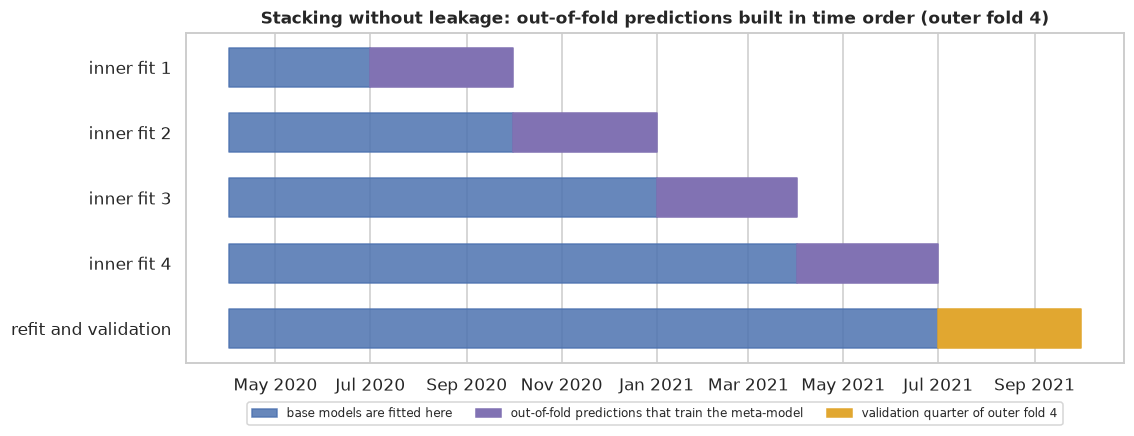

In [19]:
fig, ax = plt.subplots(figsize=(11, 3.9))
d2n = mdates.date2num
quarters = STACK_QUARTERS[4]
for i, (a, b) in enumerate(quarters):
    y0 = len(quarters) + 1 - i
    ax.broken_barh([(d2n(BURN_IN_END), d2n(a) - d2n(BURN_IN_END))], (y0 - 0.3, 0.6), color=C_NORMAL, alpha=0.85)
    ax.broken_barh([(d2n(a), d2n(b) - d2n(a))], (y0 - 0.3, 0.6), color=C_PURPLE)
f4 = FOLDS[3]
ax.broken_barh([(d2n(BURN_IN_END), d2n(f4["lo"]) - d2n(BURN_IN_END))], (0.7, 0.6), color=C_NORMAL, alpha=0.85)
ax.broken_barh([(d2n(f4["lo"]), d2n(f4["hi"]) - d2n(f4["lo"]))], (0.7, 0.6), color=C_ORANGE)
ax.set_yticks(list(range(len(quarters) + 1, 1, -1)) + [1])
ax.set_yticklabels([f"inner fit {i + 1}" for i in range(len(quarters))] + ["refit and validation"])
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_NORMAL, alpha=0.85), plt.Rectangle((0, 0), 1, 1, color=C_PURPLE), plt.Rectangle((0, 0), 1, 1, color=C_ORANGE)],
          labels=["base models are fitted here", "out-of-fold predictions that train the meta-model", "validation quarter of outer fold 4"], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
ax.set_title("Stacking without leakage: out-of-fold predictions built in time order (outer fold 4)")
savefig(fig, "05_3_stacking_design")

The Naive Bayes coefficient ranges from -0.001 to 0.023 across folds, compared with
0.56 to 0.66 for logistic regression and 0.31 to 0.47 for the tree. These are
regression coefficients on the logit inputs, not percentages or weights constrained to sum to one. Because the base predictions
are correlated, the coefficients should not be interpreted as independent measures of each model's importance.

The meta-training sets contain between 67,788 and 227,500 sessions. The chronological construction
keeps each base model's fitting rows earlier than the rows it predicts. Feature-set and configuration choices still use the
four development folds, so the reported stacking score has the model-selection optimism described in Section 6.4.

### 5.4 Does each ensemble improve on the individual models?

The table gives paired PR-AUC differences, fold by fold. For stacking, the references are its three base models. For the
forest and boosting, the standalone decision tree is a reference single-tree classifier; it is not one of their fitted trees,
and their tree settings differ. These comparisons measure predictive gains, rather than isolating variance or bias reduction.

In [20]:
FINAL = {"Logistic regression": CHOSEN["Logistic regression"], "Naive Bayes": CHOSEN["Naive Bayes"], "Decision tree": CHOSEN["Decision tree"],
         "Random forest": CHOSEN["Random forest"], "Gradient boosting": CHOSEN["Gradient boosting"], "Stacking": STACK_LABEL}
table = metric_table(list(FINAL.values()))
fold_cols = [c for c in table.columns if c != "mean"]
pairs = [("Random forest", "Decision tree"), ("Gradient boosting", "Decision tree"), ("Gradient boosting", "Random forest"),
         ("Stacking", "Logistic regression"), ("Stacking", "Naive Bayes"), ("Stacking", "Decision tree")]
rows, ensemble_diffs = [], {}
for ensemble, constituent in pairs:
    d, s = paired(table.loc[FINAL[ensemble], fold_cols], table.loc[FINAL[constituent], fold_cols])
    ensemble_diffs[f"{ensemble} − {constituent}"] = d
    rows.append({"comparison": f"{ensemble} − {constituent}", "PR-AUC difference (mean)": s["mean difference"], "folds won": s["folds won"],
                 "smallest fold": s["smallest difference"], "largest fold": s["largest difference"]})
display(pd.DataFrame(rows).set_index("comparison").style.format({"PR-AUC difference (mean)": "{:+.4f}", "smallest fold": "{:+.4f}", "largest fold": "{:+.4f}"}))

,PR-AUC difference (mean),folds won,smallest fold,largest fold
comparison,,,,
Random forest − Decision tree,+0.0250,4 of 4,+0.0221,+0.0289
Gradient boosting − Decision tree,+0.0284,4 of 4,+0.0252,+0.0315
Gradient boosting − Random forest,+0.0034,3 of 4,-0.0015,+0.0089
Stacking − Logistic regression,+0.0180,4 of 4,+0.0122,+0.0211
Stacking − Naive Bayes,+0.0854,4 of 4,+0.0636,+0.1043
Stacking − Decision tree,+0.0131,4 of 4,+0.0116,+0.0158


The forest and boosting improve on the standalone decision tree in every fold, with mean PR-AUC gains of
+0.025 and +0.028. These results support using ensembles here, although
the differences do not separately prove how much comes from averaging, sequential fitting or the different tree settings.

Stacking improves on logistic regression by +0.018, on the tree by +0.013,
and on Naive Bayes by +0.085, averaged over the folds. Its mean PR-AUC is 0.610, below both tree ensembles.
Gradient boosting differs from the forest by +0.0034 on average, within our practical tolerance.

In [21]:
log_decision("5", "Ensembles",
             "Random forest (bagging), gradient boosting (boosting) and stacking of LR + NB + DT with a logistic-regression meta-model; no voting.",
             "One ensemble per principle (variance reduction, bias reduction, model combination); stacking is compared with its base models and the tree ensembles with the standalone tree reference (Section 5.4).")
log_decision("5", "Temporal stacking",
             "Meta-training predictions come from inner expanding quarters of each fold's training window; the first quarter is training-only; sessions with a label unknown at the fold start are removed.",
             "Assertions in the code check that every inner model is fitted on sessions that ended before the predicted quarter; a random inner CV would let later sessions shape earlier predictions.")
log_decision("5", "Boosting without early stopping",
             "Fixed number of iterations; no internal early stopping.",
             "early_stopping=False in both factories; the runner checks that every boosting fit uses its specified number of iterations.")

---
## 6. Comparison and conclusions

### 6.1 All models under the Task 2 protocol

The table puts the two baselines and the six models side by side with the aggregation rules of Task 2 (Section 8): the unweighted mean PR-AUC ranks the
models, and the weighted mean, the standard deviation across folds, the worst fold and the trend describe how stable the result is. The columns `gain over B1` and `folds won vs B1`
compare each model with the baseline B1 fold by fold; the final column reports runtime.

In [22]:
NAMES = {BASELINES[0]: "B0 no skill", BASELINES[1]: "B1 post failure rate (7 days)",
         **{label: f"{name} ({label})" if name != "Stacking" else label for name, label in FINAL.items()}}
ALL_MODELS = BASELINES + list(FINAL.values())
weights = fold_table["validation sessions"]
all_metrics = pd.concat(METRICS)
pr_all = metric_table(ALL_MODELS)
fold_cols = [c for c in pr_all.columns if c != "mean"]

rows = []
for label in ALL_MODELS:
    s = summarise_folds(pr_all.loc[label, fold_cols].to_numpy(), weights.to_numpy())
    other = all_metrics[all_metrics["model"] == label][["lift", "ROC-AUC", "Brier", "log-loss", "seconds"]].mean()
    d, ps = paired(pr_all.loc[label, fold_cols], pr_all.loc[BASELINES[1], fold_cols])
    rows.append({"model": NAMES[label], "PR-AUC mean": s["mean (unweighted)"], "weighted": s["mean (weighted by validation sessions)"],
                 "std": s["std across folds"], "worst fold": s["worst fold"], "trend": s["trend per fold"],
                 "lift": other["lift"], "ROC-AUC": other["ROC-AUC"], "Brier": other["Brier"], "log-loss": other["log-loss"],
                 "gain over B1": ps["mean difference"], "folds won vs B1": ps["folds won"], "seconds per fold": other["seconds"]})
comparison = pd.DataFrame(rows).set_index("model").sort_values("PR-AUC mean", ascending=False)
display(comparison.style.format({"PR-AUC mean": "{:.3f}", "weighted": "{:.3f}", "std": "{:.3f}", "worst fold": "{:.3f}", "trend": "{:+.3f}", "lift": "{:.2f}",
                                 "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}", "gain over B1": "{:+.3f}", "seconds per fold": "{:.1f}"}, na_rep="—"))
print("PR-AUC by fold:")
display(pr_all.rename(index=NAMES).loc[comparison.index].style.format("{:.3f}"))

,PR-AUC mean,weighted,std,worst fold,trend,lift,ROC-AUC,Brier,log-loss,gain over B1,folds won vs B1,seconds per fold
model,,,,,,,,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.626,0.632,0.038,0.575,+0.020,3.50,0.836,0.102,0.337,+0.115,4 of 4,3.2
Random forest (RF leaf=50),0.622,0.629,0.042,0.567,+0.022,3.48,0.835,0.102,0.339,+0.112,4 of 4,12.6
Stacking (LR + NB + DT),0.610,0.617,0.041,0.556,+0.022,3.41,0.831,0.104,0.343,+0.100,4 of 4,14.1
Decision tree (DT depth=8),0.597,0.604,0.041,0.544,+0.023,3.34,0.824,0.105,0.347,+0.087,4 of 4,2.5
Logistic regression (LR C=0.01),0.593,0.599,0.042,0.534,+0.020,3.31,0.825,0.106,0.350,+0.082,4 of 4,2.1
Naive Bayes (NB),0.525,0.531,0.037,0.472,+0.012,2.93,0.814,0.172,0.839,+0.015,3 of 4,0.7
B1 post failure rate (7 days),0.511,0.516,0.042,0.456,+0.021,2.85,0.772,0.118,0.385,+0.000,0 of 4,—
B0 no skill,0.181,0.185,0.021,0.162,+0.014,1.01,0.504,0.148,0.472,-0.329,0 of 4,—


PR-AUC by fold:


,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.618,0.575,0.650,0.660,0.626
Random forest (RF leaf=50),0.615,0.567,0.646,0.662,0.622
Stacking (LR + NB + DT),0.602,0.556,0.636,0.648,0.610
Decision tree (DT depth=8),0.586,0.544,0.624,0.635,0.597
Logistic regression (LR C=0.01),0.590,0.534,0.615,0.630,0.593
Naive Bayes (NB),0.539,0.472,0.531,0.559,0.525
B1 post failure rate (7 days),0.499,0.456,0.547,0.540,0.511
B0 no skill,0.172,0.162,0.181,0.210,0.181


The ranking by mean PR-AUC is: Gradient boosting 0.626; Random forest 0.622; Stacking 0.610; Decision tree 0.597; Logistic regression 0.593; Naive Bayes 0.525; B1 post failure rate 0.511; B0 no skill 0.181.
The mean difference between gradient boosting and the forest is +0.0034, inside the practical tolerance.
Naive Bayes beats B1 in 3 of 4 folds; the other learned models beat it in every fold.

Gradient boosting improves on B1 by +0.119, +0.119, +0.103, +0.120 across the four quarters,
with a mean gain of +0.115. Its mean lift is 3.50, against 2.85 for B1.
The models show a broadly similar pattern of performance across quarters. Similar fold standard deviations do not establish
equal stability, and the shared trends do not isolate the effects of prevalence, longer training windows and other changes
in the data. The weighted means are also reported, so the ranking can be checked against differences in fold sizes.

For probabilities, gradient boosting has a Brier score of 0.102 and log-loss 0.337; the forest has
0.102 and 0.339. Naive Bayes has worse probability losses than the constant prior (Section 4.3).
The final column reports fitting and prediction time on this machine, which varies between runs. Stacking repeats the base
fits for its inner quarters; its extra cost has not produced a gain over the tree ensembles here.

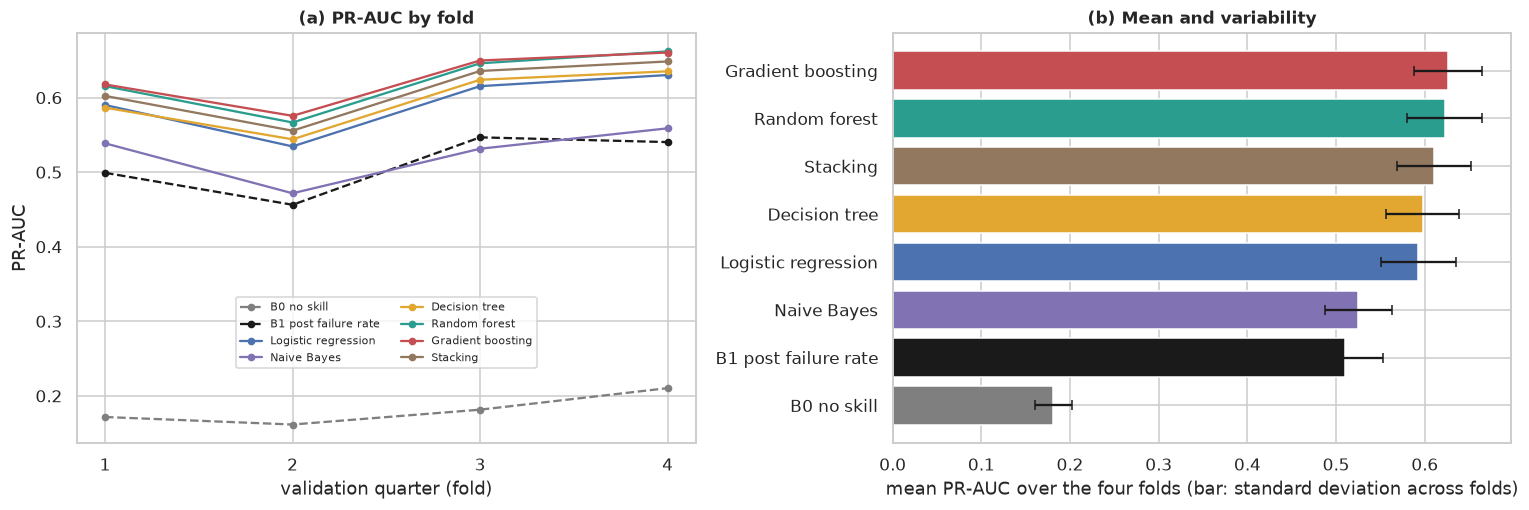

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
palette = {BASELINES[0]: C_GREY, BASELINES[1]: "k", FINAL["Logistic regression"]: C_NORMAL, FINAL["Naive Bayes"]: C_PURPLE, FINAL["Decision tree"]: C_ORANGE,
           FINAL["Random forest"]: C_GREEN, FINAL["Gradient boosting"]: C_ABN, FINAL["Stacking"]: "#937860"}
for label in ALL_MODELS:
    axes[0].plot(range(1, 5), pr_all.loc[label, fold_cols], marker="o", ms=4, color=palette[label], ls="--" if label in BASELINES else "-", label=NAMES[label].split(" (")[0])
axes[0].set_xticks(range(1, 5)); axes[0].set_xlabel("validation quarter (fold)"); axes[0].set_ylabel("PR-AUC")
axes[0].set_title("(a) PR-AUC by fold"); axes[0].legend(fontsize=7, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 0.17))
order = comparison.index[::-1]
inverse = {v: k for k, v in NAMES.items()}
axes[1].barh([n.split(" (")[0] for n in order], comparison.loc[order, "PR-AUC mean"], xerr=comparison.loc[order, "std"], color=[palette[inverse[n]] for n in order], capsize=3)
axes[1].set_xlabel("mean PR-AUC over the four folds (bar: standard deviation across folds)"); axes[1].set_title("(b) Mean and variability")
fig.tight_layout()
savefig(fig, "06_1_model_comparison")

Panel (a) shows how the ranking changes across quarters. Panel (b) reports the mean and standard deviation across those
quarters. Its error bars describe temporal variation; they are not confidence intervals for model differences. The paired
comparisons in Section 5.4 and the baseline-comparison columns are more useful for assessing small gaps between models.

### 6.2 What the alerts would look like

The operational measures of Task 2 show what the ranking means for an operator who can review a fixed share of the sessions. The first table gives the
mean precision and recall over the folds at each alert budget, and the second the counts per 1,000 sessions for the model at the top of the ranking.

In [24]:
rows = []
for label in ALL_MODELS:
    sub = all_metrics[all_metrics["model"] == label]
    row = {"model": NAMES[label]}
    for q in ALERT_BUDGETS:
        row[f"precision @{q:.0%}"] = sub[f"precision @{q:.0%}"].mean()
        row[f"recall @{q:.0%}"] = sub[f"recall @{q:.0%}"].mean()
    rows.append(row)
operational = pd.DataFrame(rows).set_index("model").loc[comparison.index]
display(operational.style.format("{:.3f}"))

best_label = inverse[comparison.index[0]]
sub = all_metrics[all_metrics["model"] == best_label]
counts = pd.DataFrame({f"budget {q:.0%}": {"alerts per 1,000": sub[f"alerts per 1,000 @{q:.0%}"].mean(), "correct alerts per 1,000": sub[f"correct alerts per 1,000 @{q:.0%}"].mean(),
                                          "false alerts per 1,000": sub[f"false alerts per 1,000 @{q:.0%}"].mean(), "missed per 1,000": sub[f"missed per 1,000 @{q:.0%}"].mean()}
                       for q in ALERT_BUDGETS})
b1 = all_metrics[all_metrics["model"] == BASELINES[1]]
counts_b1 = pd.DataFrame({f"budget {q:.0%}": {"correct alerts per 1,000": b1[f"correct alerts per 1,000 @{q:.0%}"].mean(), "false alerts per 1,000": b1[f"false alerts per 1,000 @{q:.0%}"].mean(),
                                             "missed per 1,000": b1[f"missed per 1,000 @{q:.0%}"].mean()} for q in ALERT_BUDGETS})
print(f"Counts per 1,000 sessions, mean over the folds, for {NAMES[best_label]}:")
display(counts.style.format("{:.1f}"))
print("and for the baseline B1:")
display(counts_b1.style.format("{:.1f}"))

,precision @5%,recall @5%,precision @10%,recall @10%,precision @20%,recall @20%
model,,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.880,0.246,0.724,0.404,0.528,0.586
Random forest (RF leaf=50),0.875,0.245,0.721,0.402,0.528,0.587
Stacking (LR + NB + DT),0.863,0.242,0.713,0.397,0.520,0.578
Decision tree (DT depth=8),0.862,0.241,0.710,0.395,0.515,0.573
Logistic regression (LR C=0.01),0.840,0.235,0.694,0.387,0.515,0.573
Naive Bayes (NB),0.701,0.196,0.614,0.343,0.491,0.547
B1 post failure rate (7 days),0.738,0.207,0.594,0.330,0.451,0.499
B0 no skill,0.182,0.051,0.182,0.101,0.180,0.200


Counts per 1,000 sessions, mean over the folds, for Gradient boosting (HGB depth=6, lr=0.1, 200 it):


,budget 5%,budget 10%,budget 20%
"alerts per 1,000",50.0,100.0,200.0
"correct alerts per 1,000",44.0,72.4,105.5
"false alerts per 1,000",6.0,27.6,94.5
"missed per 1,000",136.1,107.7,74.5


and for the baseline B1:


,budget 5%,budget 10%,budget 20%
"correct alerts per 1,000",36.9,59.4,90.2
"false alerts per 1,000",13.1,40.6,109.8
"missed per 1,000",143.2,120.7,89.9


At a 5% alert budget, precision is 88.0% and recall 24.6%: 44.0 correct alerts, 6.0 false alerts and 136.1 missed failures per 1,000 sessions.

At a 10% alert budget, precision is 72.4% and recall 40.4%: 72.4 correct alerts, 27.6 false alerts and 107.7 missed failures per 1,000 sessions.

At a 20% alert budget, precision is 52.8% and recall 58.6%: 105.5 correct alerts, 94.5 false alerts and 74.5 missed failures per 1,000 sessions.

For comparison, B1 at 5% gives precision 73.8%, recall 20.7%,
36.9 correct alerts and 13.1 false alerts per 1,000 sessions.
The learned model catches more failures at the same workload. Nevertheless, a 5% budget still leaves most failures unflagged.
The importance of post history suggests a limitation for failures without a recent warning pattern, but we have not measured
that subgroup separately and cannot conclude that such failures are impossible to predict.

### 6.3 Conclusions

* Post history is the largest contribution (+0.294 mean PR-AUC). User history adds +0.031, positive in every fold but smaller
  in later quarters. The pooled segment analysis shows most of this benefit for returning accounts. Tariff adds no practically
  relevant gain beyond the hour; context and weather alone give mean PR-AUC 0.290.
* We keep 27 features, dropping `post_id` and redundant `tariff_period`. The user-free alternative has 16 features and mean
  PR-AUC 0.599, and remains available if account histories cannot be used.
* Logistic regression (0.593) and the single tree (0.597) perform similarly. Naive Bayes has worse
  probability losses than the constant prior. The outlier-cap comparison supports retaining Task 1's preparation without caps.
* Gradient boosting (0.626) and random forest (0.622) outperform stacking (0.610). Their difference is
  +0.0034, inside the tolerance. Gradient boosting has the highest mean and is cheaper to refit on this machine.
* Gradient boosting gains +0.115 over B1 on average, with a gain in every fold. These remain development results: the feature set
  and hyperparameters were chosen using the same folds, and the final test is still reserved.
* At a 5% alert budget, 88.0% of the best model's alerts are correct, but recall is only 24.6%. Start-time information
  supports useful monitoring priorities, with a substantial number of missed failures at small alert budgets.

### 6.4 Limitations

* The feature set and the hyperparameters were chosen with the same four folds that we use to report results, so the scores are slightly optimistic. The unbiased estimate is the evaluation on the test period, which stays untouched until the final task.
* The ablation uses gradient boosting with fixed hyperparameters. The conclusions are for that family, although the redundancy of the tariff does not depend on it.
* With four dependent temporal folds, standard deviations and trends are rough guides; we do not use them to claim statistical significance (Task 2, Section 8).
* The alert budgets are assumptions and we did not choose a decision threshold, so the calibration of the probabilities of the best models still has to be checked before a cost-based cut-off is used.
* Instance-based and kernel-based classifiers were left out by design (Section 4.1).
* Naive Bayes retains all selected inputs to avoid importing Task 1's target-based reduced list into earlier folds. Correlated
  windows remain, so its independence assumption is still weak. The log-transform list is fixed by variable meaning; all learned
  preprocessing values are fitted within the relevant outer or inner training window.
* The tolerance of 0.005 is a practical choice. The session bootstrap does not account for dependence or estimate uncertainty in paired model differences (Section 3.3).
* Without `post_id` the model can score a new post from its station and district, but its history would be empty, and every post of the folds appears in training, so this case is not tested.
* We put the concurrency variable with the user history because it describes the account. That is our choice.

---
## 7. Saved files and decision log

The results are saved so that Task 4 can reuse the selected feature set, the selected hyperparameters and the fold-by-fold metrics without
repeating the experiments.

In [25]:
for (label, fold), p in PREDS.items():
    assert len(p) == fold_table.loc[fold, "validation sessions"], (label, fold)       # one prediction per validation session
assert set(SELECTED) <= set(features_all) and "post_id" not in SELECTED and "tariff_period" not in SELECTED
assert df["start_time"].max() < TEST_START                                              # the test period was never loaded

fold_metrics = pd.concat(METRICS).reset_index(drop=True)
fold_metrics.to_csv(OUT_DIR / "task3_fold_metrics.csv", index=False)
results = {
    "protocol": "prepared/task2_protocol.json (folds, metrics, alert budgets); test rows dropped right after reading",
    "tolerance": TOLERANCE,
    "ablation": {label: {"features": len(feats), "PR-AUC mean": float(pr.loc[label, "mean"]) if label in pr.index else float(pr_c.loc[label, "mean"])}
                 for label, feats in {**STEPS, **CHECKS}.items()},
    "selected_features": SELECTED,
    "features_without_user_history": NO_USER,
    "selected_configurations": {name: label for name, label in FINAL.items()},
    "comparison": comparison.reset_index().to_dict("records"),
    "linear_view": "capped" if LINEAR_CAP else "task1",
    "linear_view_comparison": LINEAR_VIEW_COMPARISON,
}
(OUT_DIR / "task3_results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False, default=float))
decision_log = pd.DataFrame(DECISIONS)
decision_log.to_csv(OUT_DIR / "task3_decision_log.csv", index=False)
print("Saved:", OUT_DIR / "task3_results.json", OUT_DIR / "task3_fold_metrics.csv", OUT_DIR / "task3_decision_log.csv", "| figures in", FIG_DIR)
display(decision_log.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Saved: prepared/task3_results.json prepared/task3_fold_metrics.csv prepared/task3_decision_log.csv | figures in prepared/figures_task3


section,topic,decision,evidence
3,Ablation design,"Four nested sets S1 to S4 with one fixed, untuned gradient-boosting model; paired fold differences with a tolerance of 0.005.","Reference model handles categories, NaN and interactions; the tolerance is practical; the descriptive session bootstrap does not establish significance (Section 3.3)."
3,Selected feature set,"27 features: S4 without `post_id` and `tariff_period` (calendar, station and district, weather, post history, user history, concurrency).","Removing post_id changed mean PR-AUC by +0.0107, with gains in 4 of 4 folds; tariff removal is inside the tolerance. Post history adds +0.294 and user history +0.031 on average (Sections 3.2 and 3.4)."
3,No new features,No feature is added to the 29 start-time features of the Task 2 protocol.,The start-time columns were chosen in Task 1 (Sections 9 and 12); the post history alone carries most of the signal (Section 3.2); a new history feature would need its own leakage check.
4,Individual models,"Logistic regression (linear), Categorical Naive Bayes (probabilistic) and a CART decision tree. k-NN and kernel SVM are left out.","Mixed, skewed inputs and 270k training rows make k-NN and an RBF SVM too slow without subsampling that discards the history; the other three cover three principles."
4,Hyperparameters of the individual models,Highest mean PR-AUC; a simpler configuration within 0.005 is kept. Logistic regression: C = 0.01 (stronger penalty); tree: depth 8.,"The practical tolerance is 0.005, read with paired fold differences; it is not a significance threshold (Section 3.3). Grids are in Section 4.3."
4,Outlier caps,"No caps: the linear view keeps the Task 1 preparation (log transform, no capping).","Caps minus Task 1 preparation: mean PR-AUC -0.0001, 1 of 4 folds won, tolerance 0.005 (Section 4.4)."
4,Category codes for trees,The decision tree and the random forest keep the Task 1 ordinal codes for station and district; gradient boosting reads them as categories.,"Only 13 stations and 3 districts remain after post_id is dropped, and two threshold splits isolate any single code, so the arbitrary order blocks no partition (MINDD-05 advises against imposing an order on unordered categories); gradient boosting has native categorical support."
5,Ensembles,"Random forest (bagging), gradient boosting (boosting) and stacking of LR + NB + DT with a logistic-regression meta-model; no voting.","One ensemble per principle (variance reduction, bias reduction, model combination); stacking is compared with its base models and the tree ensembles with the standalone tree reference (Section 5.4)."
5,Temporal stacking,Meta-training predictions come from inner expanding quarters of each fold's training window; the first quarter is training-only; sessions with a label unknown at the fold start are removed.,Assertions in the code check that every inner model is fitted on sessions that ended before the predicted quarter; a random inner CV would let later sessions shape earlier predictions.
5,Boosting without early stopping,Fixed number of iterations; no internal early stopping.,early_stopping=False in both factories; the runner checks that every boosting fit uses its specified number of iterations.
